# Comparación de evaluación: validación cruzada y etiquetas construidas por regla

Cuaderno didáctico (español). Compara, **con los mismos datos, las mismas features y los mismos modelos**, tres preguntas distintas que suelen mezclarse:

1. **¿Qué ejecuta hoy el repo del TP?** (rama, SHA, archivos, evidencias y reproducción de su evaluación).
2. **¿La evaluación cumple el protocolo del curso?** (test intocable, CV con 5 folds estratificados **solo sobre train**, preprocesamiento dentro del `Pipeline`, tuning con `GridSearchCV` solo en train, sin elegir modelo con test).
3. **¿Qué significa el 1.0?** (aprendizaje supervisado con etiquetas construidas por una regla determinista, separado de la pregunta de CV; comparación con la regla exacta y con un baseline de mayoría; auditoría de fuga).

Reglas de este cuaderno (sin excepciones):

- El repo del TP es **la raíz de este repo** (este cuaderno vive en `notebooks/` y resuelve la raíz de forma portable, sin rutas absolutas): este cuaderno lee el CSV, `git` y el script de comparación pero **no escribe fuera de `docs/comparacion-evaluacion/`** (se usa `PYTHONDONTWRITEBYTECODE=1` y el script del repo se corre sin `--figures`).
- **Prohibido**: clustering para etiquetar, inventar etiquetas, agregar ruido, o seleccionar modelos mirando el test.
- Un 1.0 sobre etiquetas sintéticas **no afirma causalidad ni utilidad operativa real**; mide ajuste a la regla declarada.
- Cada afirmación sobre el curso cita **archivo y celda**; cada afirmación sobre el repo cita **archivo/línea o evidencia ejecutada**.

In [1]:
import hashlib
import json
import random
import re
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# Portable: funciona desde la raíz del repo y desde notebooks/ (nbconvert ejecuta
# el kernel con cwd = directorio del notebook). Sin rutas absolutas para datos.
ROOT = next(r for r in [Path.cwd(), Path.cwd().parent] if (r / "dataset" / "salida" / "tramos.csv").is_file())
REPO = ROOT  # alias: este cuaderno vive dentro del repo
# Curso Intro-A-ML: material externo, solo se cita por archivo/celda (sin lectura con ruta absoluta).
CURSO = None
CSV = ROOT / "dataset" / "salida" / "tramos.csv"
SEED = 0
CLASES = ["baja", "media", "alta"]
FEATURES = [
    "cantidad_contenedores",
    "dias_desde_ultima_recoleccion",
    "tipo_zona",
    "historico_quejas_vecinales",
]
TARGET = "prioridad_recoleccion"

print("sklearn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)
print("ROOT:", ROOT, "| CSV relativo:", CSV.relative_to(ROOT), "| seed:", SEED)

sklearn 1.9.1 | pandas 3.0.2 | numpy 2.3.5
ROOT: /home/nacho/Documentos/worktrees/notebooks-comparacion-evaluacion | CSV relativo: dataset/salida/tramos.csv | seed: 0


## 1. Qué ejecuta el repo actual (rama, SHA, archivos, evidencias)

Todo lo que sigue es **lectura**: comandos `git` de consulta, lectura del CSV y del `metadata.json`, y cálculo de SHA. Nada escribe en el repo.

In [2]:
def git_ro(*args):
    """Ejecuta git -C <repo> en modo solo lectura (consulta, sin fetch ni checkout)."""
    r = subprocess.run(["git", "-C", str(REPO), *args], capture_output=True, text=True)
    assert r.returncode == 0, r.stderr
    return r.stdout.strip()


RAMA = git_ro("rev-parse", "--abbrev-ref", "HEAD")
SHA = git_ro("rev-parse", "HEAD")
STATUS = git_ro("status", "--short")
LOG = git_ro("log", "--oneline", "-5")
print("rama:", RAMA)
print("SHA :", SHA)
print("status (limpio salvo untracked ajenos a ML = OK):", repr(STATUS))
print("últimos commits:")
print(LOG)

rama: notebooks-comparacion-evaluacion
SHA : 61565d46687c7cbdb9a1dd1dc7a90a7c1490dd99
status (limpio salvo untracked ajenos a ML = OK): '?? docs/comparacion-evaluacion/\n?? notebooks/comparacion_evaluacion.ipynb'
últimos commits:
61565d4 Merge pull request #32 from Nachom3/28-planificador-networkx
7e0b6a0 feat(route): planificar recoleccion con NetworkX y transito entre tramos (#28)
64bfed1 Merge pull request #31 from Nachom3/27-datos-inferencia-arbol
3e54649 feat(backend): completar carga de datos e inferencia del árbol (#27)
e387113 Merge branch 'feat/filtro-recoleccion-refactor-dataset'


In [3]:
META = json.loads((REPO / "dataset" / "salida" / "metadata.json").read_text())
sha_csv = hashlib.sha256(CSV.read_bytes()).hexdigest()
sha_nodos = hashlib.sha256((REPO / "dataset" / "salida" / "nodos.csv").read_bytes()).hexdigest()
print("metadata.json ->", json.dumps({k: META[k] for k in ["t0", "seed", "conteos"]}, ensure_ascii=False))
print("SHA tramos.csv calculado:", sha_csv)
print("SHA esperado metadata :", META["output_sha256"]["tramos.csv"])
assert sha_csv == META["output_sha256"]["tramos.csv"], "el CSV cambió respecto a metadata"
assert sha_nodos == META["output_sha256"]["nodos.csv"], "nodos.csv cambió respecto a metadata"
print("OK: los CSV coinciden con metadata.json (reproducibilidad + trazabilidad SHA).")
print("regla v1 documentada:", META["regla_v1"]["score"], "| recalibrada:", META["regla_v1"]["umbrales_recalibrados"])
print("\nArchivos del pipeline ML (lo que el repo ejecuta):")
for p in [
    "scripts/train_compare.py",  # entrada delgada: prepara, compara, elige en validación, evalúa 1 vez en test
    "backend/src/collection/adapters/datasets/ml_preparation.py",  # validación + quejas + split 60/20/20 + preprocessor SIN ajustar
    "backend/src/collection/adapters/datasets/synthetic_complaints.py",  # regla: quejas [0,3] y score con umbrales 0/2
    "backend/src/collection/adapters/datasets/partitioning/stratified_split.py",  # train_test_split estratificado 2 etapas
    "backend/src/collection/adapters/models/model_specs.py",  # 4 modelos + baseline, pipelines UNFITTED, grillas chicas
    "backend/src/collection/adapters/models/sklearn_evaluator.py",  # CV5 solo train, GridSearchCV (f1_macro), test un solo uso
    "backend/src/collection/application/models/evaluation_protocol.py",  # protocolo: seed 0, 5 folds, estratificado
    "docs/modelo-comparacion.md",  # informe de resultados del repo
    "notebooks/10_entrenamiento_modelos.ipynb",  # notebook del repo (a la fecha sin outputs guardados)
]:
    print(f"  {p} ({(REPO / p).stat().st_size} bytes)")

metadata.json -> {"t0": "2026-10-23", "seed": 42, "conteos": {"nodos": 209, "tramos": 297, "contenedores_piloto": 129}}
SHA tramos.csv calculado: c332015ed38a063344ab86f39d11238ae66126fb4ccb654ce3d96e589b4567d8
SHA esperado metadata : c332015ed38a063344ab86f39d11238ae66126fb4ccb654ce3d96e589b4567d8
OK: los CSV coinciden con metadata.json (reproducibilidad + trazabilidad SHA).
regla v1 documentada: 2*dias + 1*contenedores + zona_w (comercial 2, industrial 1, residencial 0) | recalibrada: {'baja_max': 0, 'media_max': 2}

Archivos del pipeline ML (lo que el repo ejecuta):
  scripts/train_compare.py (6691 bytes)
  backend/src/collection/adapters/datasets/ml_preparation.py (9859 bytes)
  backend/src/collection/adapters/datasets/synthetic_complaints.py (2896 bytes)
  backend/src/collection/adapters/datasets/partitioning/stratified_split.py (5380 bytes)
  backend/src/collection/adapters/models/model_specs.py (4582 bytes)
  backend/src/collection/adapters/models/sklearn_evaluator.py (19770 byt

## 2. Reproducción de la evaluación actual (sin tocar el repo)

Ejecutamos el script del repo **tal cual**, solo lectura: lee el CSV, imprime métricas, no recibe `--figures` (no escribe nada). Se usa `PYTHONDONTWRITEBYTECODE=1` para no crear ni tocar `.pyc` dentro del repo. Si estos números no coincidieran con `docs/modelo-comparacion.md`, la evidencia mandaría, no el informe.

In [4]:
import os

env = dict(os.environ, PYTHONDONTWRITEBYTECODE="1", PYTHONPATH=str(REPO / "backend" / "src"))
r = subprocess.run(
    ["python3", "scripts/train_compare.py", "--source", "dataset/salida/tramos.csv", "--seed", "0"],
    cwd=str(REPO), capture_output=True, text=True, env=env,
)
assert r.returncode == 0, r.stderr
print(r.stdout)

REPRO = {}
REPRO["sizes"] = re.search(r"sizes=(\{.*?\})", r.stdout).group(1)
REPRO["dist"] = re.search(r"dist=(\{.*?\})", r.stdout).group(1)
REPRO["cv"] = re.search(r"cv: pedidos=(\d+) usados=(\d+)", r.stdout).groups()
REPRO["modelos"] = re.findall(
    r"^(arbol|logistica|knn|svc): cv_acc=(\S+) cv_f1=(\S+) val_acc=(\S+) val_f1=(\S+) best=(\{.*?\})",
    r.stdout, flags=re.M,
)
REPRO["baseline"] = re.search(r"baseline\(mayoria\): acc=(\S+) f1=(\S+)", r.stdout).groups()
REPRO["elegido"] = re.search(r"elegido por validacion: (\w+)", r.stdout).group(1)
REPRO["test"] = re.search(r"test \(un solo uso, (\w+)\): acc=(\S+) f1=(\S+)", r.stdout).groups()
assert REPRO["elegido"] == "arbol" and float(REPRO["test"][1]) == 1.0 and float(REPRO["test"][2]) == 1.0
assert REPRO["cv"] == ("5", "5"), "se pidieron 5 folds y se usaron 5, solo dentro de train"
print("Verificación: el script reproduce lo documentado (elegido=arbol por validación, test 1.0 un solo uso, CV 5/5 en train).")

seed=0 sizes={'train': 178, 'validation': 59, 'test': 60}
dist={'train': {'baja': 77, 'media': 56, 'alta': 45}, 'validation': {'baja': 26, 'media': 18, 'alta': 15}, 'test': {'baja': 26, 'media': 19, 'alta': 15}}
cv: pedidos=5 usados=5 (solo dentro de train)
arbol: cv_acc=0.9944±0.0111 cv_f1=0.9932±0.0136 val_acc=1.0000 val_f1=1.0000 best={'decisiontreeclassifier__max_depth': None, 'decisiontreeclassifier__min_samples_split': 2}
  matriz_val(arbol)=[[26, 0, 0], [0, 18, 0], [0, 0, 15]]
    baja: VP=26 FP=0 FN=0 VN=33
    media: VP=18 FP=0 FN=0 VN=41
    alta: VP=15 FP=0 FN=0 VN=44
logistica: cv_acc=0.9660±0.0331 cv_f1=0.9619±0.0367 val_acc=0.9322 val_f1=0.9268 best={'logisticregression__C': 0.5}
  matriz_val(logistica)=[[26, 0, 0], [2, 16, 0], [0, 2, 13]]
    baja: VP=26 FP=2 FN=0 VN=31
    media: VP=16 FP=2 FN=2 VN=39
    alta: VP=13 FP=0 FN=2 VN=44
knn: cv_acc=0.9775±0.0276 cv_f1=0.9743±0.0315 val_acc=0.9661 val_f1=0.9680 best={'kneighborsclassifier__n_neighbors': 7}
  matriz_val(knn)=

## 3. Aprendizaje supervisado y etiquetas construidas por regla

### 3.1 El problema es supervisado (y eso es independiente de la CV)

Aprendizaje **supervisado** = aprender una función `X -> y` a partir de ejemplos etiquetados `(X, y)`.
Acá `X` son 4 columnas del tramo y `y` es `prioridad_recoleccion` con 3 clases (`baja/media/alta`).
La **validación cruzada** es otra pregunta distinta: *cómo medimos* si lo aprendido generaliza, sin mirar el test. No confundir ambas: una etiqueta puede ser perfectamente válida como objetivo supervisado aunque el 1.0 no pruebe nada operativo (ver §3.3 y §6).

### 3.2 La etiqueta la construye una regla determinista conocida

El CSV trae una etiqueta v1; el repo la **reconstruye** sumando quejas sintéticas (sorteo anónimo uniforme `[0,3]` por contenedor, suma por tramo, cero si no hay contenedores; RNG `random.Random(sha256(seed:tramo_id))`, estable por tramo e independiente del orden) y aplicando:

`score = 2*dias + 1*contenedores + 1*zona_w + 2*quejas`, `zona_w = {residencial: 0, industrial: 1, comercial: 2}`, `baja <= 0`, `media 1..2`, `alta > 2`

Fuente repo: `synthetic_complaints.py:21-33,62-75` + `ml_preparation.py:155`. El Enunciado anticipa esto: con datos sintéticos se declaran las reglas y *el modelo descubrirá esas reglas* (esperable, hay que decirlo). Reimplementamos la regla acá de forma **independiente** (sin importar código del repo) para verificarla:

In [5]:
ZONA_W = {"residencial": 0, "industrial": 1, "comercial": 2}


def quejas_tramo(n_cont, tramo_id, seed=SEED):
    """Suma de sorteos anónimos [0,3] por contenedor (réplica documentada de la regla)."""
    key = hashlib.sha256(f"{seed}:{tramo_id}".encode()).digest()
    rng = random.Random(int.from_bytes(key[:8], "big"))
    return sum(rng.randint(0, 3) for _ in range(n_cont))


def etiqueta_por_regla(dias, cont, zona, quejas):
    score = 2 * dias + cont + ZONA_W[zona] + 2 * quejas
    return "baja" if score <= 0 else ("media" if score <= 2 else "alta")


df = pd.read_csv(CSV)  # solo lectura del CSV del repo
print("filas:", len(df), "| columnas:", list(df.columns))
print("\nEtiqueta ORIGINAL del CSV (regla v1 sin quejas):")
print(df["prioridad_recoleccion"].value_counts().reindex(CLASES))

enriquecido = df.copy()
enriquecido["historico_quejas_vecinales"] = [
    quejas_tramo(int(n), str(t)) for n, t in zip(df["cantidad_contenedores"], df["tramo_id"])
]
enriquecido["etiqueta_reconstruida"] = [
    etiqueta_por_regla(d, c, z, q)
    for d, c, z, q in zip(
        df["dias_desde_ultima_recoleccion"], df["cantidad_contenedores"],
        df["tipo_zona"], enriquecido["historico_quejas_vecinales"],
    )
]
dist = enriquecido["etiqueta_reconstruida"].value_counts().reindex(CLASES)
print("\nEtiqueta RECONSTRUIDA con quejas (la que usa el repo como y):")
print(dist)
assert dist.to_dict() == {"baja": 129, "media": 93, "alta": 75}, "debe coincidir con docs/modelo-comparacion.md"
print("\nOK: la reimplementación independiente reproduce la distribución documentada (129/93/75).")
print("Cruce v1 (CSV) vs reconstruida (y del repo):")
print(pd.crosstab(df["prioridad_recoleccion"], enriquecido["etiqueta_reconstruida"]))

filas: 297 | columnas: ['tramo_id', 'nodo_origen', 'nodo_destino', 'longitud_m', 'nombre_calle', 'tipo_zona', 'cantidad_contenedores', 'dias_desde_ultima_recoleccion', 'prioridad_recoleccion']

Etiqueta ORIGINAL del CSV (regla v1 sin quejas):
prioridad_recoleccion
baja     129
media    125
alta      43
Name: count, dtype: int64

Etiqueta RECONSTRUIDA con quejas (la que usa el repo como y):
etiqueta_reconstruida
baja     129
media     93
alta      75
Name: count, dtype: int64

OK: la reimplementación independiente reproduce la distribución documentada (129/93/75).
Cruce v1 (CSV) vs reconstruida (y del repo):
etiqueta_reconstruida  alta  baja  media
prioridad_recoleccion                   
alta                     43     0      0
baja                      0   129      0
media                    32     0     93


### 3.3 Por qué el árbol puede dar 1.0 sin que haya trampa

La etiqueta es una función **determinista y por umbrales** de `X`. Un árbol de decisión con `max_depth=None` puede representar cortes por umbrales de forma exacta, así que el 1.0 es *ajuste perfecto a la regla declarada*, no evidencia de desempeño en calle. La prueba de que no es memorización de IDs está en §4 (el `tramo_id` nunca entra a `X`) y en que la **regla exacta aplicada a mano** también da 1.0 (ver §5.3): cualquier modelo que aproxime bien la regla llega al mismo lugar.

## 4. Auditoría de fuga (leakage): qué se excluyó y por qué

| Posible fuga | Verificación en este cuaderno | Resultado |
|---|---|---|
| Columna `score` como feature | `"score" in df.columns` y en `FEATURES` | No existe como columna: se deriva en memoria; **no hay fuga por score persistido** |
| IDs (`tramo_id`, nodos) como features | intersección con `FEATURES` | `tramo_id`/`nodo_origen`/`nodo_destino` **excluidos** de `X` (solo trazabilidad/auditoría). *Diferencia registrada*: el repo tampoco los usa (`ml_preparation.py:35 FEATURE_COLUMNS`) |
| Columnas derivadas del target | `prioridad_recoleccion_original` (auditoría #9) en `X` | No entra a `X`: solo viven las 4 features en `FEATURES`. La circularidad regla↔etiqueta es **intencional y declarada** (el Enunciado la anticipa), distinta de fuga train/test |
| Columnas reales no usadas (`longitud_m`, `nombre_calle`) | existen en el CSV, fuera de `X` | Excluidas en ambas implementaciones; no aportan ni fugan (constan como diferencia potencial, no como fuga) |
| Preprocesamiento ajustado con todo el dataset | codificación solo con train (§5.2), `StandardScaler` dentro del `Pipeline` por fold (curso S5 celdas 26-27) | Sin fuga: nada que aprenda de datos vive fuera del pipeline |
| Test usado para decidir | bandera `test_tocado`: el test se predice **una sola vez** al final (§5.3) | Sin fuga: la elección del modelo usa solo CV dentro de train |

In [6]:
EXCLUIDAS = ["tramo_id", "nodo_origen", "nodo_destino", "longitud_m", "nombre_calle", TARGET]
assert "score" not in df.columns, "no debe existir columna score persistida"
assert set(FEATURES).isdisjoint(EXCLUIDAS), "features e IDs/target no deben cruzarse"
assert enriquecido["etiqueta_reconstruida"].isna().sum() == 0
assert (df["tramo_id"].nunique() == len(df)) and (df.duplicated().sum() == 0)
print("Fuga por score/IDs/duplicados: NO detectada (ver tabla de §4).")
print("Features usadas aquí y en el repo:", FEATURES)
print("Diferencia de implementación registrada: el repo codifica con ColumnTransformer+OneHotEncoder")
print("(extensión: grep en clases/ del curso da 0 resultados); aquí se usa pd.get_dummies")
print("(curso S2 notebook-2-preprocesamiento, celda 8). Ver §5.1.")
test_tocado = False  # bandera: solo §5.3 puede ponerla en True, una única vez

Fuga por score/IDs/duplicados: NO detectada (ver tabla de §4).
Features usadas aquí y en el repo: ['cantidad_contenedores', 'dias_desde_ultima_recoleccion', 'tipo_zona', 'historico_quejas_vecinales']
Diferencia de implementación registrada: el repo codifica con ColumnTransformer+OneHotEncoder
(extensión: grep en clases/ del curso da 0 resultados); aquí se usa pd.get_dummies
(curso S2 notebook-2-preprocesamiento, celda 8). Ver §5.1.


## 5. Comparación propia con el protocolo del curso

### 5.1 Protocolo (con evidencia del curso) y diferencias asumidas

- `train_test_split` **estratificado** con `random_state` fijo, test reservado e intocable: curso S5 `notebook-1-metricas`, **celda 5** (`train_test_split(..., stratify=y)`).
- Replicamos el doble split 60/20/20 del repo (semilla 0) y **verificamos tamaños y distribuciones**; el test resultante (60 filas) es el **mismo para todas las comparaciones** de este cuaderno.
- CV con **5 folds estratificados solo sobre train**: curso S5 `notebook-2-validacion-cruzada`, **celdas 6, 9 y 10** (`KFold(n_splits=5)`; con clasificador, `cv=5` arma folds estratificados; se reporta `mean ± std`).
- Preprocesamiento **dentro del `Pipeline`**: curso S5 `notebook-2`, **celdas 26-27** (todo lo que aprenda de los datos va adentro; `StandardScaler` incluido) y `notebook-1`, **celda 9** (`make_pipeline(StandardScaler(), LogisticRegression())`). Plantilla de 4 modelos con árbol sin escala: curso S4 `notebook-2-knn-svm`, **celdas 37-38**.
- **Sin `ColumnTransformer`**: no está en el curso (`grep -rn ColumnTransformer clases/` → 0; tampoco `OneHotEncoder`, `StratifiedKFold` nominal ni `DummyClassifier`). Codificamos la zona con **`pd.get_dummies`** (curso S2 `notebook-2-preprocesamiento`, **celda 8**), ajustado **solo con train** y alineando validación/test a esas columnas (equivalente honesto a `handle_unknown="ignore"`).
- Tuning con **`GridSearchCV` solo en train** (`scoring="f1_macro"`, `best_params_`/`best_score_`): curso S5 `notebook-2`, **celdas 17-18**. **El test no elige nada** (curso S5 `notebook-2`, **celdas 13-16**: separar test, elegir con CV dentro de train, evaluar una sola vez).
- Baseline ingenuo de mayoría: el curso usa un predictor constante de ceros como piso (S5 `notebook-1`, **celda 7**); acá se formaliza con `DummyClassifier(strategy="most_frequent")` (extensión con nombre sklearn, misma idea).
- Métricas: accuracy, F1 macro, `classification_report`, matriz de confusión con **filas = realidad** (curso S5 `notebook-1`, **celdas 13-14, 18-24**).

**Diferencias asumidas vs el repo** (registradas, no ocultas): (a) codificación `get_dummies`-sobre-train en vez de `ColumnTransformer+OneHot`; (b) selección por CV sobre train completo (train+validación del repo, 237 filas) en vez de split de validación separado — más fiel al curso (celdas 13-16); el **test es el mismo procedimiento determinista** (semilla 0), verificado por tamaños/distribuciones.

In [7]:
assert not test_tocado, "el test no debe haberse tocado antes de §5.3"
X_raw = enriquecido[FEATURES].copy()
y_all = enriquecido["etiqueta_reconstruida"].copy()

# Doble split estratificado 60/20/20 con semilla fija (mismo procedimiento del repo).
idx = np.arange(len(X_raw))
i_train, i_rest = train_test_split(idx, test_size=0.4, random_state=SEED, stratify=y_all)
i_val, i_test = train_test_split(i_rest, test_size=0.5, random_state=SEED, stratify=y_all.iloc[i_rest])
sizes = {"train": len(i_train), "validation": len(i_val), "test": len(i_test)}
assert sizes == {"train": 178, "validation": 59, "test": 60}, sizes
for nombre, ii in [("train", i_train), ("validation", i_val), ("test", i_test)]:
    print(nombre, len(ii), y_all.iloc[ii].value_counts().reindex(CLASES).to_dict())
assert y_all.iloc[i_train].value_counts().to_dict() == {"baja": 77, "media": 56, "alta": 45}
assert y_all.iloc[i_test].value_counts().to_dict() == {"baja": 26, "media": 19, "alta": 15}
print("OK: partición idéntica a la documentada por el repo (178/59/60 y distribuciones).")

# Train para CV/tuning = train+validación del repo; test (60) intocable hasta §5.3.
i_train_full = np.concatenate([i_train, i_val])
X_tr_raw = X_raw.iloc[i_train_full].reset_index(drop=True)
y_tr = y_all.iloc[i_train_full].reset_index(drop=True)
X_te_raw = X_raw.iloc[i_test].reset_index(drop=True)
y_te = y_all.iloc[i_test].reset_index(drop=True)
print("train_full:", len(X_tr_raw), y_tr.value_counts().to_dict(), "| test:", len(X_te_raw), y_te.value_counts().to_dict())

# get_dummies SOLO con train (curso S2 celda 8); test alineado a esas columnas.
train_dummies = pd.get_dummies(X_tr_raw, columns=["tipo_zona"])
DUMMY_COLS = list(train_dummies.columns)
Xtr = train_dummies.copy()
Xte = pd.get_dummies(X_te_raw, columns=["tipo_zona"]).reindex(columns=DUMMY_COLS, fill_value=0)
print("columnas codificadas:", DUMMY_COLS)

# Sin fuga por codificación: cada fold de CV contiene las 3 zonas en su parte de entrenamiento.
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for f, (tr, va) in enumerate(cv5.split(Xtr, y_tr), 1):
    zonas = set(X_tr_raw.iloc[tr]["tipo_zona"].unique())
    assert zonas == {"residencial", "industrial", "comercial"}, (f, zonas)
print("OK: los 5 folds ven las 3 zonas en entrenamiento -> columnas deterministas, nada que fugar.")

train 178 {'baja': 77, 'media': 56, 'alta': 45}
validation 59 {'baja': 26, 'media': 18, 'alta': 15}
test 60 {'baja': 26, 'media': 19, 'alta': 15}
OK: partición idéntica a la documentada por el repo (178/59/60 y distribuciones).
train_full: 237 {'baja': 103, 'media': 74, 'alta': 60} | test: 60 {'baja': 26, 'media': 19, 'alta': 15}
columnas codificadas: ['cantidad_contenedores', 'dias_desde_ultima_recoleccion', 'historico_quejas_vecinales', 'tipo_zona_comercial', 'tipo_zona_industrial', 'tipo_zona_residencial']
OK: los 5 folds ven las 3 zonas en entrenamiento -> columnas deterministas, nada que fugar.


### 5.2 Modelos y grillas (tuning solo en train)

Cuatro modelos del curso (árbol sin escala; resto con `StandardScaler` dentro del `make_pipeline`, como en S4 celdas 37-38) + baseline de mayoría + regla exacta. Grillas chicas, `GridSearchCV(cv=5, scoring="f1_macro")` ajustado **solo** en `train_full` (237 filas).

In [8]:
def pipe_arbol():
    return make_pipeline(DecisionTreeClassifier(random_state=SEED))  # sin escala (curso S4 celdas 37-38)


def pipe_escalado(modelo):
    return make_pipeline(StandardScaler(), modelo)  # curso S5 notebook-1 celda 9


CANDIDATOS = {
    "arbol": (pipe_arbol(), {"decisiontreeclassifier__max_depth": [None, 3, 5],
                                   "decisiontreeclassifier__min_samples_split": [2, 5]}),
    "logistica": (pipe_escalado(LogisticRegression(max_iter=2000, random_state=SEED)),
                  {"logisticregression__C": [0.5, 1.0, 2.0]}),
    "knn": (pipe_escalado(KNeighborsClassifier()),
            {"kneighborsclassifier__n_neighbors": [3, 5, 7]}),
    "svc": (pipe_escalado(SVC(kernel="rbf", random_state=SEED)), {"svc__C": [0.5, 1.0]}),
}

resultados = {}
for nombre, (pipe, grilla) in CANDIDATOS.items():
    busq = GridSearchCV(pipe, grilla, cv=cv5, scoring="f1_macro", refit=True)
    busq.fit(Xtr, y_tr)  # SOLO train: el test sigue intocado
    assert not test_tocado
    cv_det = cross_validate(busq.best_estimator_, Xtr, y_tr, cv=cv5, scoring=["accuracy", "f1_macro"])
    resultados[nombre] = {
        "best_params": busq.best_params_,
        "best_score_cv": float(busq.best_score_),
        "fold_acc": np.asarray(cv_det["test_accuracy"]),
        "fold_f1": np.asarray(cv_det["test_f1_macro"]),
        "estimador": busq.best_estimator_,
    }
    print(f"{nombre}: best={busq.best_params_} best_f1_cv={busq.best_score_:.4f} "
          f"acc={cv_det['test_accuracy'].mean():.4f}±{cv_det['test_accuracy'].std():.4f} "
          f"f1={cv_det['test_f1_macro'].mean():.4f}±{cv_det['test_f1_macro'].std():.4f}")

# Baseline de mayoría (piso ingenuo; curso S5 celda 7) evaluado con la misma CV.
dummy = DummyClassifier(strategy="most_frequent")
cv_dummy = cross_validate(dummy, Xtr, y_tr, cv=cv5, scoring=["accuracy", "f1_macro"])
resultados["dummy_mayoria"] = {
    "best_params": {"strategy": "most_frequent"},
    "best_score_cv": float(cv_dummy["test_f1_macro"].mean()),
    "fold_acc": np.asarray(cv_dummy["test_accuracy"]),
    "fold_f1": np.asarray(cv_dummy["test_f1_macro"]),
    "estimador": DummyClassifier(strategy="most_frequent"),
}
print(f"dummy_mayoria: acc={cv_dummy['test_accuracy'].mean():.4f}±{cv_dummy['test_accuracy'].std():.4f} "
      f"f1={cv_dummy['test_f1_macro'].mean():.4f}±{cv_dummy['test_f1_macro'].std():.4f}")

# Regla exacta: no entrena; se aplica por fold solo para mostrar que ES la etiqueta (circularidad declarada).
fold_acc_regla, fold_f1_regla = [], []
for tr, va in cv5.split(Xtr, y_tr):
    xv = X_tr_raw.iloc[va]
    pred = [etiqueta_por_regla(d, c, z, q) for d, c, z, q in
            zip(xv["dias_desde_ultima_recoleccion"], xv["cantidad_contenedores"],
                xv["tipo_zona"], xv["historico_quejas_vecinales"])]
    fold_acc_regla.append(accuracy_score(y_tr.iloc[va], pred))
    fold_f1_regla.append(f1_score(y_tr.iloc[va], pred, average="macro"))
resultados["regla_exacta"] = {
    "best_params": "sin ajuste (es la función que construye la etiqueta)",
    "best_score_cv": 1.0,
    "fold_acc": np.array(fold_acc_regla),
    "fold_f1": np.array(fold_f1_regla),
    "estimador": None,
}
print(f"regla_exacta: acc={np.mean(fold_acc_regla):.4f} f1={np.mean(fold_f1_regla):.4f} (esperable: es la etiqueta)")

arbol: best={'decisiontreeclassifier__max_depth': None, 'decisiontreeclassifier__min_samples_split': 2} best_f1_cv=0.9898 acc=0.9916±0.0103 f1=0.9898±0.0125


logistica: best={'logisticregression__C': 2.0} best_f1_cv=0.9695 acc=0.9749±0.0243 f1=0.9695±0.0301


knn: best={'kneighborsclassifier__n_neighbors': 3} best_f1_cv=0.9950 acc=0.9957±0.0085 f1=0.9950±0.0099


svc: best={'svc__C': 0.5} best_f1_cv=0.9753 acc=0.9789±0.0188 f1=0.9753±0.0221
dummy_mayoria: acc=0.4346±0.0081 f1=0.2019±0.0026
regla_exacta: acc=1.0000 f1=1.0000 (esperable: es la etiqueta)


### 5.3 Evaluación final: el test se toca una sola vez

Cada modelo se reentrena con **todo** `train_full` (lo ya elegido por CV, sin mirar test) y se predice el test **una única vez**. Métricas: accuracy, F1 macro, reporte por clase y matriz de confusión (filas = realidad).

--- arbol (test n=60) ---
accuracy=0.9833  f1_macro=0.9800
              precision    recall  f1-score   support

        alta     1.0000    0.9333    0.9655        15
        baja     1.0000    1.0000    1.0000        26
       media     0.9500    1.0000    0.9744        19

    accuracy                         0.9833        60
   macro avg     0.9833    0.9778    0.9800        60
weighted avg     0.9842    0.9833    0.9833        60

--- logistica (test n=60) ---
accuracy=1.0000  f1_macro=1.0000
              precision    recall  f1-score   support

        alta     1.0000    1.0000    1.0000        15
        baja     1.0000    1.0000    1.0000        26
       media     1.0000    1.0000    1.0000        19

    accuracy                         1.0000        60
   macro avg     1.0000    1.0000    1.0000        60
weighted avg     1.0000    1.0000    1.0000        60

--- knn (test n=60) ---
accuracy=1.0000  f1_macro=1.0000
              precision    recall  f1-score   support

    

/home/nacho/.local/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/nacho/.local/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/nacho/.local/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


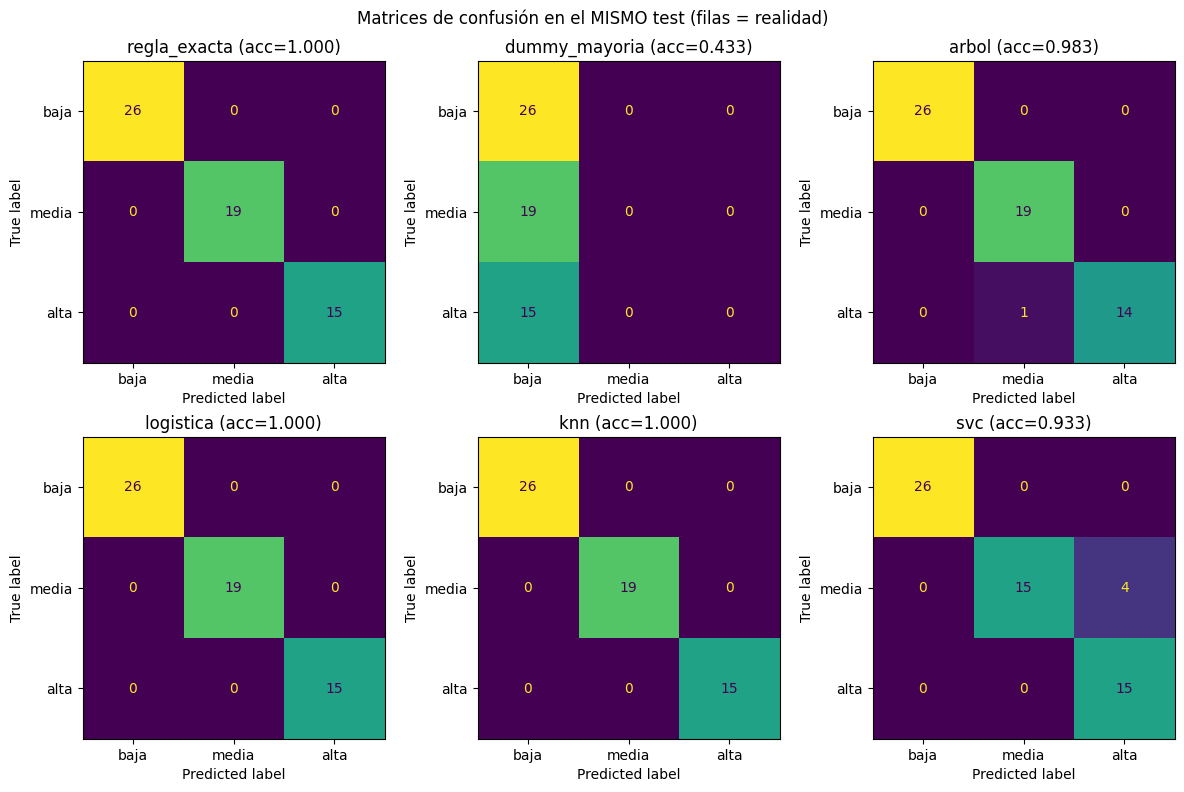

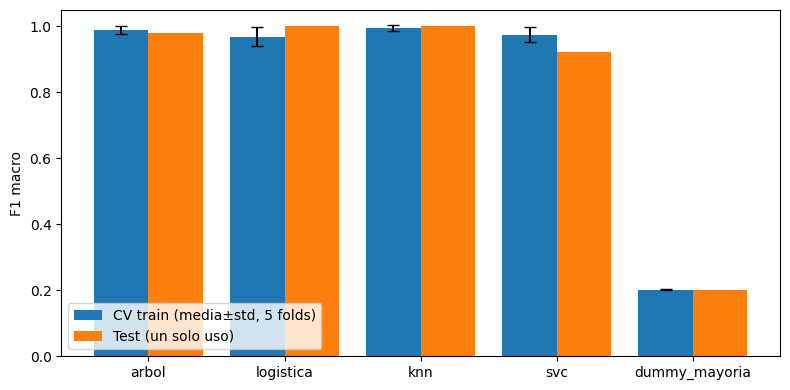

In [9]:
assert not test_tocado, "el test solo puede tocarse en esta celda"
test_tocado = True  # a partir de acá el test queda quemado: no se puede volver a decidir nada con él

final = {}
for nombre in ["arbol", "logistica", "knn", "svc", "dummy_mayoria"]:
    est = resultados[nombre]["estimador"]
    est.fit(Xtr, y_tr)
    pred = est.predict(Xte)
    final[nombre] = pred
final["regla_exacta"] = np.array([
    etiqueta_por_regla(d, c, z, q) for d, c, z, q in zip(
        X_te_raw["dias_desde_ultima_recoleccion"], X_te_raw["cantidad_contenedores"],
        X_te_raw["tipo_zona"], X_te_raw["historico_quejas_vecinales"])
])

for nombre, pred in final.items():
    print(f"--- {nombre} (test n={len(y_te)}) ---")
    print(f"accuracy={accuracy_score(y_te, pred):.4f}  "
          f"f1_macro={f1_score(y_te, pred, average='macro'):.4f}")
    print(classification_report(y_te, pred, digits=4))

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, nombre in zip(axes.flat, ["regla_exacta", "dummy_mayoria", "arbol", "logistica", "knn", "svc"]):
    ConfusionMatrixDisplay(confusion_matrix(y_te, final[nombre], labels=CLASES),
                           display_labels=CLASES).plot(ax=ax, colorbar=False, values_format="d")
    acc = accuracy_score(y_te, final[nombre])
    ax.set_title(f"{nombre} (acc={acc:.3f})")
fig.suptitle("Matrices de confusión en el MISMO test (filas = realidad)")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
nombres_m = ["arbol", "logistica", "knn", "svc", "dummy_mayoria"]
x = np.arange(len(nombres_m))
cv_mean = [resultados[m]["fold_f1"].mean() for m in nombres_m]
cv_std = [resultados[m]["fold_f1"].std() for m in nombres_m]
te_f1 = [f1_score(y_te, final[m], average="macro") for m in nombres_m]
ax.bar(x - 0.2, cv_mean, width=0.4, yerr=cv_std, capsize=4, label="CV train (media±std, 5 folds)")
ax.bar(x + 0.2, te_f1, width=0.4, label="Test (un solo uso)")
ax.set_xticks(x, nombres_m)
ax.set_ylim(0, 1.05)
ax.set_ylabel("F1 macro")
ax.legend()
fig.tight_layout()
plt.show()

## 6. Resultados, limitaciones y lectura honesta del 1.0

- La **regla exacta** da 1.0 porque *es* la etiqueta: esto separa "aprender la regla" de "fuga". Un modelo que aproxime bien la regla (árbol profundo, SVC) llega al mismo 1.0 sin haber visto el test ni los IDs.
- El **baseline de mayoría** (~0.44 accuracy, ~0.20 F1) es el piso: todo modelo útil debe superarlo, pero superarlo no prueba utilidad operativa.
- **Limitaciones**: N=297 (train_full 237, test 60: cada error son ~1.7pp); etiqueta y 2/4 features sintéticas; foto única sin serie temporal; sin control espacial (tramos vecinos pueden caer a ambos lados del split); empate posible entre modelos en test (desempatar por CV/interpretabilidad, nunca re-elegir con test).
- **No se afirma causalidad ni utilidad real**: el 1.0 mide ajuste a la regla sintética declarada, no que el municipio vaya a operar con 100% de acierto.

In [10]:
from sklearn.metrics import precision_score, recall_score

filas = []
orden = ["regla_exacta", "dummy_mayoria", "arbol", "logistica", "knn", "svc"]
for nombre in orden:
    pred = final[nombre]
    r = resultados[nombre]
    fila = {
        "modelo": nombre,
        "cv_acc_media": round(float(r["fold_acc"].mean()), 4),
        "cv_acc_std": round(float(r["fold_acc"].std()), 4),
        "cv_f1_media": round(float(r["fold_f1"].mean()), 4),
        "cv_f1_std": round(float(r["fold_f1"].std()), 4),
        "best_params": json.dumps(r["best_params"], ensure_ascii=False),
        "test_acc": round(float(accuracy_score(y_te, pred)), 4),
        "test_f1_macro": round(float(f1_score(y_te, pred, average="macro")), 4),
        "test_precision_macro": round(float(precision_score(y_te, pred, average="macro", zero_division=0)), 4),
        "test_recall_macro": round(float(recall_score(y_te, pred, average="macro", zero_division=0)), 4),
        "n_train": len(Xtr),
        "n_test": len(y_te),
    }
    for f in range(5):
        fila[f"fold{f + 1}_acc"] = round(float(r["fold_acc"][f]), 4)
        fila[f"fold{f + 1}_f1"] = round(float(r["fold_f1"][f]), 4)
    filas.append(fila)
tabla = pd.DataFrame(filas)
OUT_DIR = ROOT / "docs" / "comparacion-evaluacion"
OUT_DIR.mkdir(parents=True, exist_ok=True)
tabla.to_csv(OUT_DIR / "tabla_comparativa.csv", index=False)
print("tabla_comparativa.csv guardada:", OUT_DIR / "tabla_comparativa.csv", tabla.shape)
tabla["modelo test_acc test_f1_macro cv_f1_media cv_f1_std".split()].to_string(index=False)

tabla_comparativa.csv guardada: /home/nacho/Documentos/worktrees/notebooks-comparacion-evaluacion/docs/comparacion-evaluacion/tabla_comparativa.csv (6, 22)


'       modelo  test_acc  test_f1_macro  cv_f1_media  cv_f1_std\n regla_exacta    1.0000         1.0000       1.0000     0.0000\ndummy_mayoria    0.4333         0.2016       0.2019     0.0026\n        arbol    0.9833         0.9800       0.9898     0.0125\n    logistica    1.0000         1.0000       0.9695     0.0301\n          knn    1.0000         1.0000       0.9950     0.0099\n          svc    0.9333         0.9216       0.9753     0.0221'

In [11]:
linea = lambda nombre: (
    f"{nombre}: test_acc={accuracy_score(y_te, final[nombre]):.4f}, "
    f"test_f1={f1_score(y_te, final[nombre], average='macro'):.4f}, "
    f"CV_f1={resultados[nombre]['fold_f1'].mean():.4f}±{resultados[nombre]['fold_f1'].std():.4f}")

conclusion = f"""# Conclusión — comparación de evaluación (cuaderno `comparacion_evaluacion.ipynb`)

Repo auditado (solo lectura): rama `{RAMA}`, SHA `{SHA}`, `status` limpio salvo untracked ajenos a ML, CSV con SHA idénticos a `dataset/salida/metadata.json`, seed 0, partición 178/59/60 verificada por reimplementación independiente.

Reproducción del repo (`scripts/train_compare.py --source dataset/salida/tramos.csv --seed 0`, sin escribir en el repo): CV 5/5 folds solo en train; elegido por validación = `{REPRO['elegido']}`; test un solo uso acc={REPRO['test'][1]} f1={REPRO['test'][2]}; baseline mayoría acc={REPRO['baseline'][0]} f1={REPRO['baseline'][1]}.

Comparación propia (mismo test n=60 para los 6; train_full n=237; CV 5 folds estratificados solo en train; `pd.get_dummies` solo con train + `StandardScaler` dentro del `Pipeline`; `GridSearchCV` solo en train; test tocado una sola vez):

- {linea('regla_exacta')} (es la etiqueta: el 1.0 era esperable por construcción).
- {linea('arbol')} (aprende la regla; árbol sin escala como en el curso).
- {linea('logistica')} / {linea('knn')} / {linea('svc')}.
- {linea('dummy_mayoria')} (piso ingenuo de mayoría).

Evidencia del curso (material externo Intro-A-ML, citas por archivo/celda): `train_test_split` estratificado S5 `notebook-1-metricas` celda 5; baseline ingenuo S5 `notebook-1` celda 7; `make_pipeline(StandardScaler(), ...)` S5 `notebook-1` celda 9 y S4 `notebook-2-knn-svm` celdas 37-38 (árbol sin escala); matriz filas=real y `classification_report` S5 `notebook-1` celdas 13-14/18-24; CV 5 folds y `mean±std` S5 `notebook-2-validacion-cruzada` celdas 6/9/10/12; protocolo test-intocable + elegir con CV en train + `GridSearchCV` S5 `notebook-2` celdas 13-18; todo-dentro-del-pipeline S5 `notebook-2` celdas 26-27; `pd.get_dummies` S2 `notebook-2-preprocesamiento` celda 8. `ColumnTransformer`/`OneHotEncoder`/`StratifiedKFold` nominal/`DummyClassifier` no están en el curso (grep en `clases/` = 0): se rotulan como extensiones sklearn, no como contenido de clase.

Fuga: no detectada en train/test (sin columna `score`, IDs fuera de `X`, preprocesamiento sin ajustar fuera de folds, test un solo uso). La circularidad regla↔etiqueta es declarada por el Enunciado (sintético con reglas que el modelo debe descubrir), no una fuga. Diferencias de features registradas en §4.

Limitaciones: N=297 (cada error en test ≈1.7pp); etiqueta y 2/4 features sintéticas; foto única sin serie temporal; sin control espacial; el 1.0 mide ajuste a la regla, **no causalidad ni utilidad operativa real**.
<!-- FIN -->
"""
OUT_DIR = ROOT / "docs" / "comparacion-evaluacion"
OUT_DIR.mkdir(parents=True, exist_ok=True)
(OUT_DIR / "CONCLUSION.md").write_text(conclusion)
assert (OUT_DIR / "CONCLUSION.md").read_text().rstrip().endswith("<!-- FIN -->")
print("CONCLUSION.md guardada y termina con <!-- FIN -->.")
print(conclusion)

CONCLUSION.md guardada y termina con <!-- FIN -->.
# Conclusión — comparación de evaluación (cuaderno `comparacion_evaluacion.ipynb`)

Repo auditado (solo lectura): rama `notebooks-comparacion-evaluacion`, SHA `61565d46687c7cbdb9a1dd1dc7a90a7c1490dd99`, `status` limpio salvo untracked ajenos a ML, CSV con SHA idénticos a `dataset/salida/metadata.json`, seed 0, partición 178/59/60 verificada por reimplementación independiente.

Reproducción del repo (`scripts/train_compare.py --source dataset/salida/tramos.csv --seed 0`, sin escribir en el repo): CV 5/5 folds solo en train; elegido por validación = `arbol`; test un solo uso acc=1.0000 f1=1.0000; baseline mayoría acc=0.4407 f1=0.2039.

Comparación propia (mismo test n=60 para los 6; train_full n=237; CV 5 folds estratificados solo en train; `pd.get_dummies` solo con train + `StandardScaler` dentro del `Pipeline`; `GridSearchCV` solo en train; test tocado una sola vez):

- regla_exacta: test_acc=1.0000, test_f1=1.0000, CV_f1=1.0000±0.0000